# Amazon Products Exploratory Data Analysis

## Project Overview

This project explores an Amazon product dataset to understand customer ratings, pricing patterns, discounts, and category performance.

The analysis includes:

- Data Cleaning
- Feature Engineering
- Exploratory Data Analysis (EDA)
- Business Insights

## Import Libraries

* Import libraries for data processing, numerical operations, and visualization.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
sns.set_theme(style='whitegrid')


* Load the dataset and display the first few records for an initial overview.

In [2]:
pd.set_option('display.max_rows', None)


df = pd.read_csv("combined_dataset.csv")
df.head()

,name,main_category,sub_category,image,link,ratings,no_of_ratings,discount_price,actual_price
0,Lloyd 1.5 Ton 3 Star Inverter Split Ac (5 In 1...,appliances,Air Conditioners,https://m.media-amazon.com/images/I/31UISB90sY...,https://www.amazon.in/Lloyd-Inverter-Convertib...,4.2,"2,255","₹32,999","₹58,990"
1,LG 1.5 Ton 5 Star AI DUAL Inverter Split AC (C...,appliances,Air Conditioners,https://m.media-amazon.com/images/I/51JFb7FctD...,https://www.amazon.in/LG-Convertible-Anti-Viru...,4.2,"2,948","₹46,490","₹75,990"
2,LG 1 Ton 4 Star Ai Dual Inverter Split Ac (Cop...,appliances,Air Conditioners,https://m.media-amazon.com/images/I/51JFb7FctD...,https://www.amazon.in/LG-Inverter-Convertible-...,4.2,"1,206","₹34,490","₹61,990"
3,LG 1.5 Ton 3 Star AI DUAL Inverter Split AC (C...,appliances,Air Conditioners,https://m.media-amazon.com/images/I/51JFb7FctD...,https://www.amazon.in/LG-Convertible-Anti-Viru...,4.0,69,"₹37,990","₹68,990"
4,Carrier 1.5 Ton 3 Star Inverter Split AC (Copp...,appliances,Air Conditioners,https://m.media-amazon.com/images/I/41lrtqXPiW...,https://www.amazon.in/Carrier-Inverter-Split-C...,4.1,630,"₹34,490","₹67,790"


* Dataset Shape

In [3]:
df.shape

(551585, 9)

* Dataset Overview 
Inspect the dataset structure, data types, and missing values.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 551585 entries, 0 to 551584
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   name            551585 non-null  str  
 1   main_category   551585 non-null  str  
 2   sub_category    551585 non-null  str  
 3   image           551585 non-null  str  
 4   link            551585 non-null  str  
 5   ratings         375791 non-null  str  
 6   no_of_ratings   375791 non-null  str  
 7   discount_price  490422 non-null  str  
 8   actual_price    533772 non-null  str  
dtypes: str(9)
memory usage: 37.9 MB


* Check for duplicate records and remove them

In [5]:
df.duplicated().sum()

df.drop_duplicates(inplace=True)



 * The dataset includes image URL columns that serve only as references to product images. Since these columns contain no descriptive or numerical information useful for analysis, they were excluded to simplify the dataset and improve readability.

In [6]:
df=df.loc[:,['name','main_category','sub_category','ratings','no_of_ratings','discount_price','actual_price']]

* Remove leading and trailing whitespace from all string columns.

In [7]:
df = df.map(lambda x: x.strip() if isinstance(x, str) else x)

* Replace invalid rating values with NaN and convert the column to numeric.

In [8]:
df['ratings'] = (
    df['ratings']
    .astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df['ratings'] = pd.to_numeric(df['ratings'], errors='coerce')

* Remove currency symbols and thousands separators from the discount_price column.

In [9]:
df['discount_price'] = df['discount_price'].str.replace('₹', '', regex=False)
df['discount_price'] = df['discount_price'].str.replace(',', '', regex=False)

df['discount_price'] = pd.to_numeric(df['discount_price'], errors='coerce')

df['discount_price'].unique()

array([32999.  , 46490.  , 34490.  , ...,  3712.1 ,  1429.6 ,   651.01],
      shape=(27512,))

* Replace invalid text entries with missing values.

In [10]:
df['no_of_ratings'] = df['no_of_ratings'].replace([
    'Usually dispatched in 3 to 5 days.',
    'Usually dispatched in 9 to 10 days.',
    'Usually dispatched in 8 to 9 days.',
    'Usually dispatched in 1 to 2 months.',
    'This item will be released on August 14 2023.',
    'Only 2 left in stock.',
    'Only 1 left in stock.',
    'FREE Delivery by Amazon',
    'Usually dispatched in 2 to 3 days.',
    'Usually dispatched in 5 to 6 days.',
    'Usually dispatched in 4 to 5 days.',
    'Usually dispatched in 6 to 7 days.',
    'Usually dispatched in 7 to 8 days.',
    'Only 3 left in stock.',
    'Usually dispatched in 3 to 4 weeks.',
    'Usually dispatched in 4 to 5 weeks.',
    'Only 5 left in stock.',
    'Only 4 left in stock.',
    'Usually dispatched in 11 to 12 days.',
    'Usually dispatched in 2 to 3 weeks.'
], np.nan)

df['no_of_ratings'] = df['no_of_ratings'].str.replace(',', '', regex=False)
df['no_of_ratings'] = pd.to_numeric(df['no_of_ratings'], errors='coerce')

df['no_of_ratings'].unique()

array([2255., 2948., 1206., ..., 3329., 7141., 4406.], shape=(8285,))

* Remove currency symbols and thousands separators from the actual_price column.

In [11]:
df['actual_price'] = df['actual_price'].str.replace('₹', '', regex=False)
df['actual_price'] = df['actual_price'].str.replace(',', '', regex=False)

df['actual_price'] = pd.to_numeric(df['actual_price'], errors='coerce')

df['actual_price'].unique()

array([58990.  , 75990.  , 61990.  , ...,   608.97,  4792.  ,  8023.6 ],
      shape=(23171,))

# Missing Values

In [12]:
df.isna().sum()

name                   0
main_category          0
sub_category           0
ratings           182003
no_of_ratings     182027
discount_price     61163
actual_price       17813
dtype: int64

<Axes: >

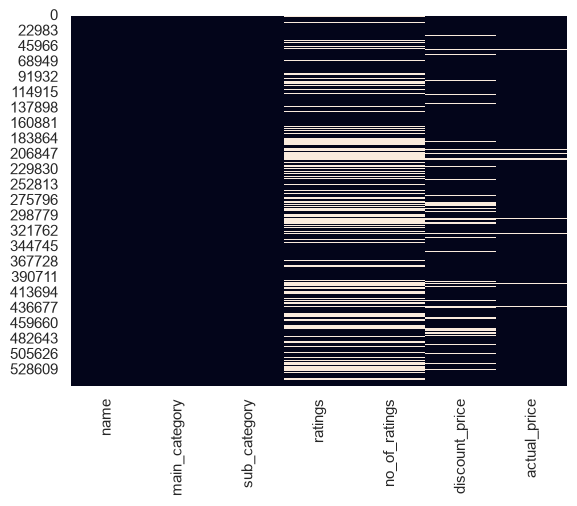

In [13]:
sns.heatmap(df.isnull(),cbar=False)

In [14]:
(df.isna().mean() * 100).sort_values(ascending=False)

no_of_ratings     33.000716
ratings           32.996365
discount_price    11.088590
actual_price       3.229421
sub_category       0.000000
name               0.000000
main_category      0.000000
dtype: float64

* The median was used to fill missing values because the numerical features are skewed. Unlike the mean, the median is less affected by outliers and provides a more representative value for skewed distributions.

<Axes: xlabel='ratings', ylabel='Count'>

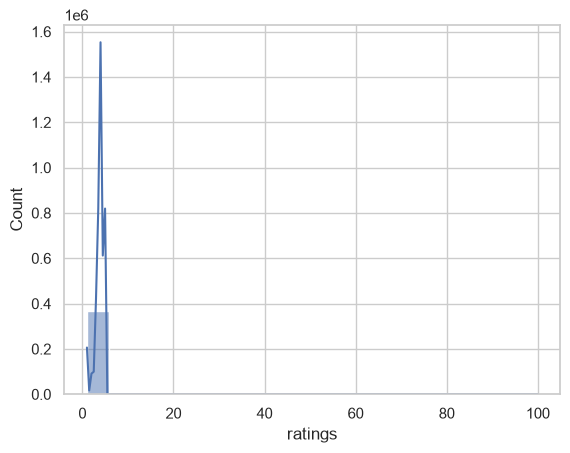

In [15]:
sns.histplot(df['ratings'],bins=20,kde=True)

In [16]:
df['ratings'] = df['ratings'].fillna(df['ratings'].median())

<Axes: xlabel='ratings', ylabel='Count'>

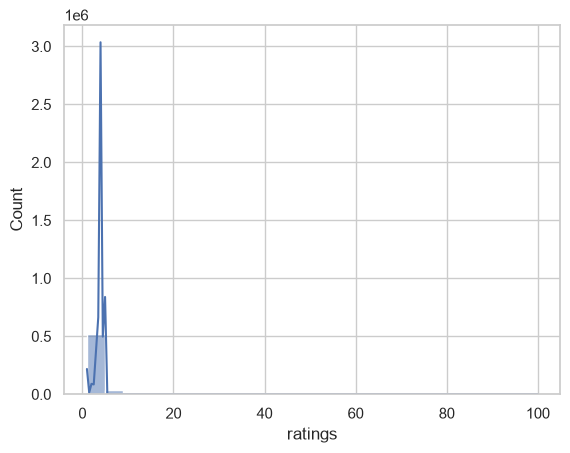

In [17]:
sns.histplot(df['ratings'], bins=25, kde=True)

<Axes: ylabel='ratings'>

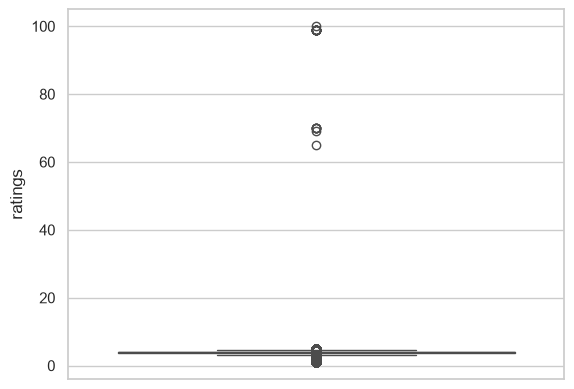

In [18]:
sns.boxplot(df['ratings'])

<Axes: xlabel='no_of_ratings', ylabel='Count'>

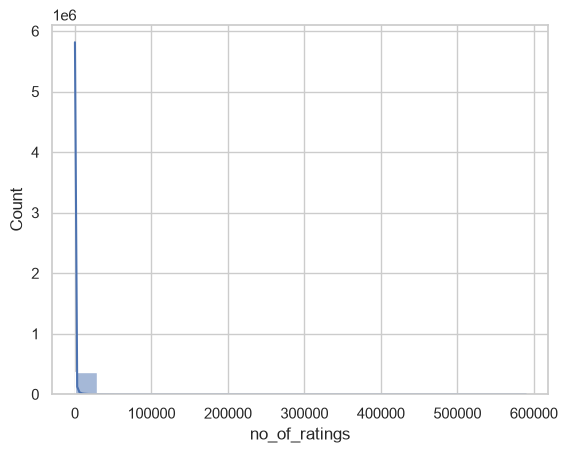

In [19]:
sns.histplot(df['no_of_ratings'],bins=20,kde=True)

In [20]:
df['no_of_ratings'] = df['no_of_ratings'].fillna(df['no_of_ratings'].median())

<Axes: xlabel='discount_price', ylabel='Count'>

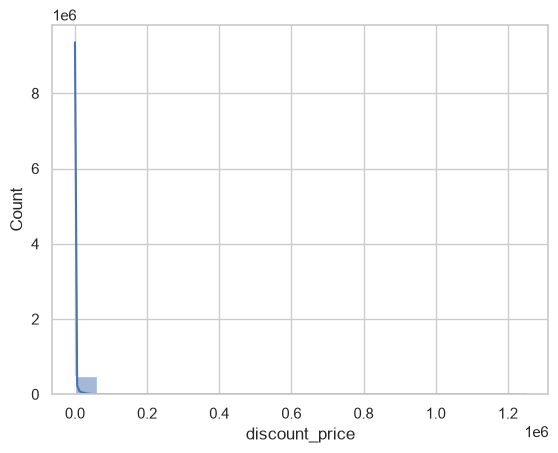

In [21]:
sns.histplot(df['discount_price'],bins=20,kde=True)

In [22]:
df['discount_price'] = df['discount_price'].fillna(df['discount_price'].median())

<Axes: xlabel='actual_price', ylabel='Count'>

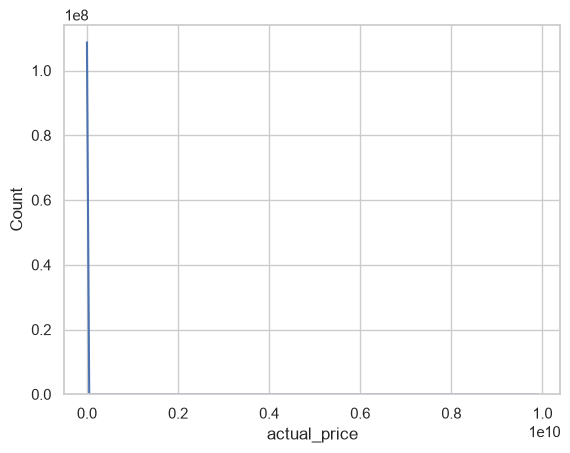

In [23]:
sns.histplot(df['actual_price'],bins=20,kde=True)

In [24]:
df['actual_price'] = df['actual_price'].fillna(df['actual_price'].median())

In [25]:
invalid_prices = (df['discount_price'] > df['actual_price']).sum()
print(f'Invalid price records: {invalid_prices}')

Invalid price records: 11959


In [26]:
df = df[df['discount_price'] <= df['actual_price']].copy()

In [27]:
df['discount_percentage'] = (
    (df['actual_price'] - df['discount_price'])
    / df['actual_price']
) * 100

In [28]:
print((df['discount_price'] > df['actual_price']).sum())

0


* The dataset is now cleaned, validated, and ready for Exploratory Data Analysis (EDA).

# Handling Skewness using Log Transformation

* ## Ratings col

In [29]:
df = df[df['ratings'] <= 5].copy()

In [30]:
(df['ratings'] > 5).sum()

np.int64(0)

<Axes: ylabel='ratings'>

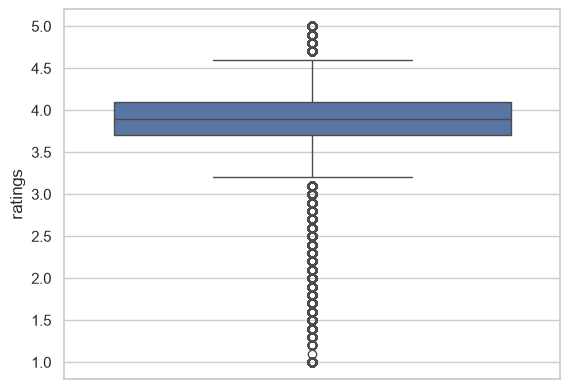

In [31]:
sns.boxplot(df['ratings'])

<Axes: xlabel='ratings', ylabel='Count'>

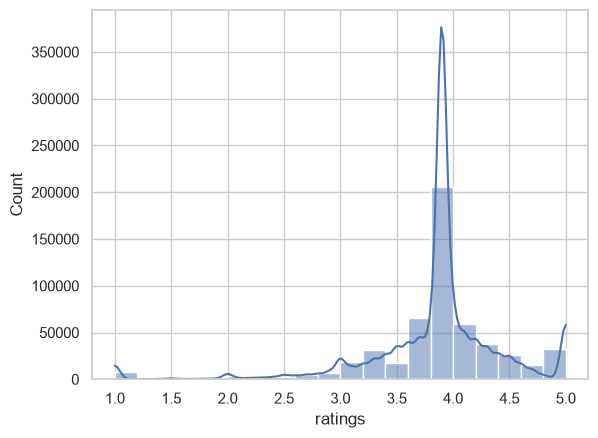

In [32]:
sns.histplot(df['ratings'],bins=20,kde=True)

* ## Actual Price col

In [33]:
df['log_actual_price'] = np.log1p(df['actual_price'])

<Axes: ylabel='log_actual_price'>

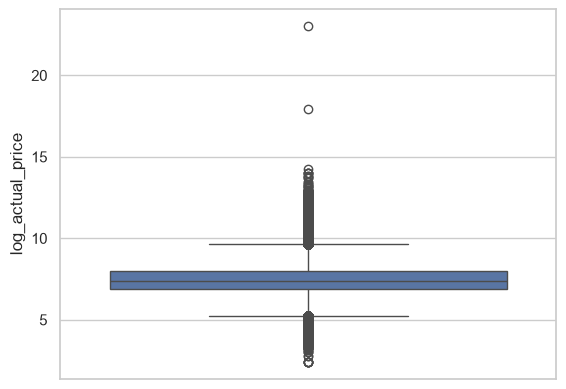

In [34]:
sns.boxplot(df['log_actual_price'])

<Axes: xlabel='log_actual_price', ylabel='Count'>

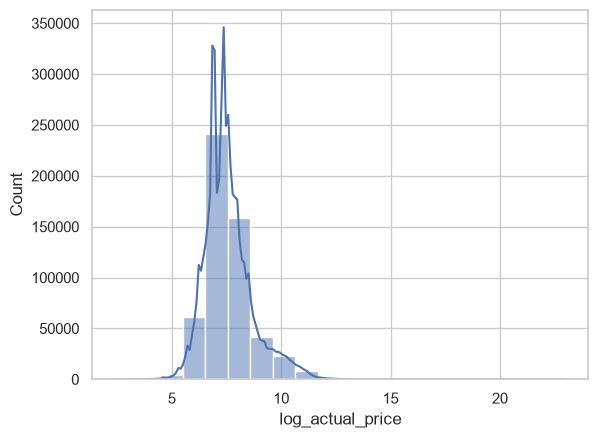

In [35]:
sns.histplot(df['log_actual_price'],bins=20,kde=True)

* ## Number Of Ratings Col

In [36]:
df['log_no_of_ratings'] = np.log1p(df['no_of_ratings'])

<Axes: ylabel='log_no_of_ratings'>

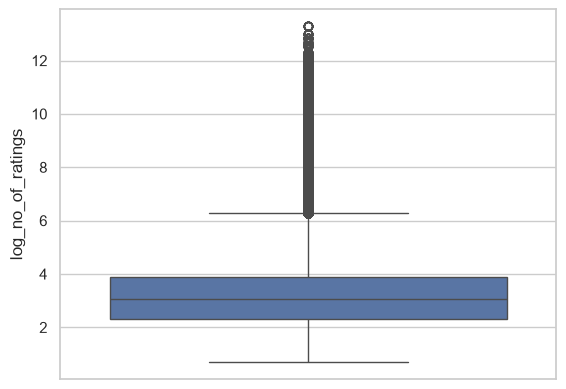

In [37]:
sns.boxplot(df['log_no_of_ratings'])

<Axes: xlabel='log_no_of_ratings', ylabel='Count'>

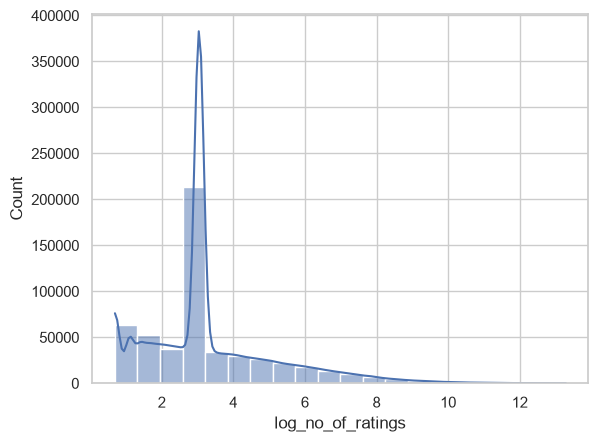

In [38]:
sns.histplot(df['log_no_of_ratings'],bins=20,kde=True)

* ## Discount Price col

In [39]:
df['log_discount_price'] = np.log1p(df['discount_price'])

<Axes: ylabel='log_discount_price'>

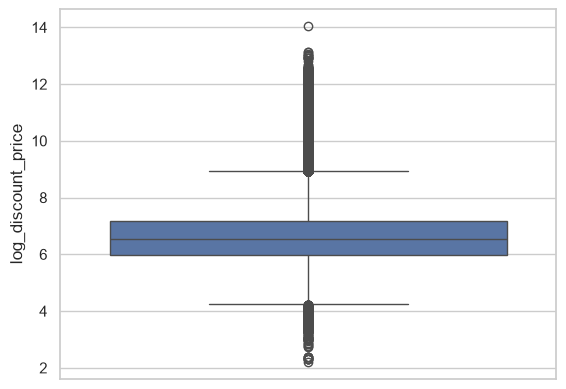

In [40]:
sns.boxplot(df['log_discount_price'])

<Axes: xlabel='log_discount_price', ylabel='Count'>

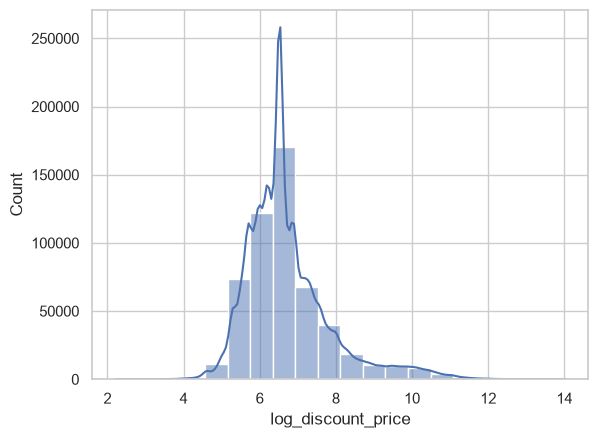

In [41]:
sns.histplot(df['log_discount_price'],bins=20,kde=True)

<Axes: ylabel='discount_percentage'>

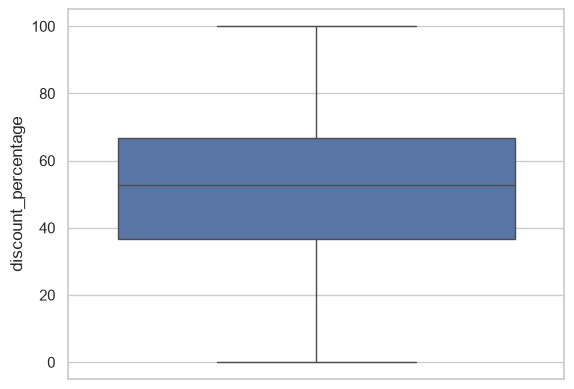

In [42]:
sns.boxplot(df['discount_percentage'])

<Axes: xlabel='discount_percentage', ylabel='Count'>

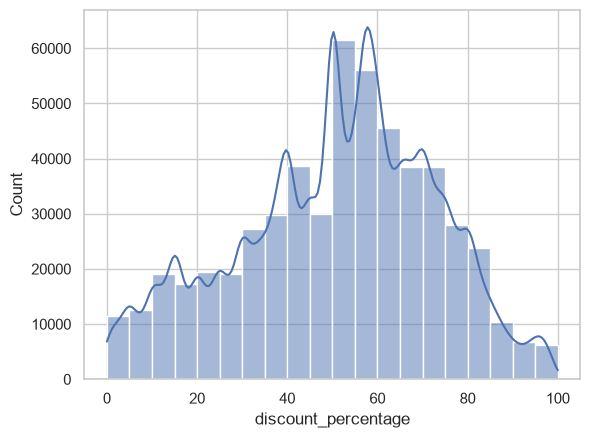

In [43]:
sns.histplot(df['discount_percentage'],bins=20,kde=True)

# Validation

In [44]:
print(df.isna().sum())
print(df.duplicated().sum())

name                   0
main_category          0
sub_category           0
ratings                0
no_of_ratings          0
discount_price         0
actual_price           0
discount_percentage    0
log_actual_price       0
log_no_of_ratings      0
log_discount_price     0
dtype: int64
35454


In [45]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ratings,539604.0,3.853024,6.203966e-01,1.000000,3.700000,3.900000,4.100000,5.000000e+00
no_of_ratings,539604.0,572.012133,7.154797e+03,1.000000,9.000000,20.000000,48.000000,5.895470e+05
discount_price,539604.0,2445.770986,9.034144e+03,8.000000,399.000000,679.000000,1294.000000,1.249990e+06
actual_price,539604.0,22905.103268,1.347739e+07,10.000000,999.000000,1599.000000,2999.000000,9.900000e+09
discount_percentage,539604.0,50.707049,2.202166e+01,0.000000,36.678893,52.869932,66.740823,9.999999e+01
log_actual_price,539604.0,7.559275,1.076298e+00,2.397895,6.907755,7.377759,8.006368,2.301580e+01
log_no_of_ratings,539604.0,3.319780,1.813995e+00,0.693147,2.302585,3.044522,3.891820,1.328711e+01
log_discount_price,539604.0,6.722008,1.121634e+00,2.197225,5.991465,6.522093,7.166266,1.403865e+01


In [46]:
df.describe(include="object").T

C:\Users\Ahmed Othman\AppData\Local\Temp\ipykernel_16860\1274302342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
name,539604,387221,Zeya Yellow Gold Ring,718
main_category,539604,20,accessories,115389
sub_category,539604,112,Jeans,19165


In [47]:
df.shape

(539604, 11)

* Final Clean Dataset

In [48]:
df.head()

,name,main_category,sub_category,ratings,no_of_ratings,discount_price,actual_price,discount_percentage,log_actual_price,log_no_of_ratings,log_discount_price
0,Lloyd 1.5 Ton 3 Star Inverter Split Ac (5 In 1...,appliances,Air Conditioners,4.2,2255.0,32999.0,58990.0,44.060010,10.985140,7.721349,10.404263
1,LG 1.5 Ton 5 Star AI DUAL Inverter Split AC (C...,appliances,Air Conditioners,4.2,2948.0,46490.0,75990.0,38.820897,11.238370,7.989221,10.747014
2,LG 1 Ton 4 Star Ai Dual Inverter Split Ac (Cop...,appliances,Air Conditioners,4.2,1206.0,34490.0,61990.0,44.361994,11.034744,7.095893,10.448454
3,LG 1.5 Ton 3 Star AI DUAL Inverter Split AC (C...,appliances,Air Conditioners,4.0,69.0,37990.0,68990.0,44.934048,11.141731,4.248495,10.545105
4,Carrier 1.5 Ton 3 Star Inverter Split AC (Copp...,appliances,Air Conditioners,4.1,630.0,34490.0,67790.0,49.122289,11.124185,6.447306,10.448454


In [49]:
df.info()

<class 'pandas.DataFrame'>
Index: 539604 entries, 0 to 551584
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   name                 539604 non-null  str    
 1   main_category        539604 non-null  str    
 2   sub_category         539604 non-null  str    
 3   ratings              539604 non-null  float64
 4   no_of_ratings        539604 non-null  float64
 5   discount_price       539604 non-null  float64
 6   actual_price         539604 non-null  float64
 7   discount_percentage  539604 non-null  float64
 8   log_actual_price     539604 non-null  float64
 9   log_no_of_ratings    539604 non-null  float64
 10  log_discount_price   539604 non-null  float64
dtypes: float64(8), str(3)
memory usage: 49.4 MB


# 📊 Exploratory Data Analysis (EDA)

## Distribution of Product Ratings

This histogram visualizes the distribution of customer ratings to understand the overall satisfaction level across products.

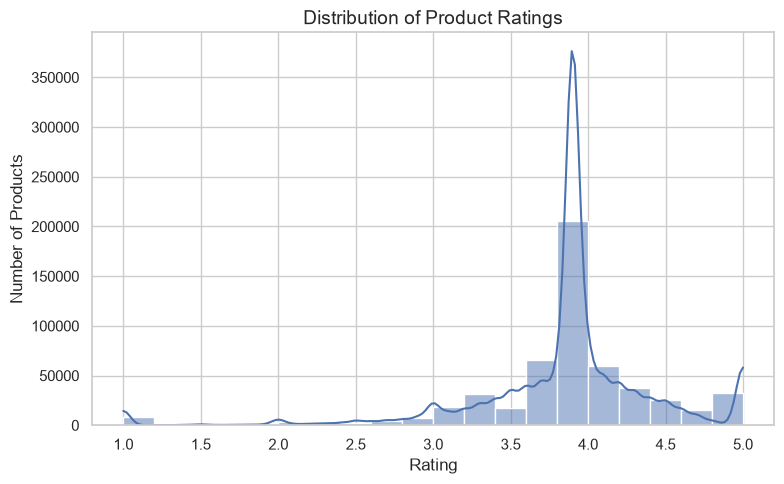

In [50]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='ratings',
    bins=20,
    kde=True
    
)

plt.title('Distribution of Product Ratings', fontsize=14)
plt.xlabel('Rating')
plt.ylabel('Number of Products')

plt.tight_layout()

plt.show()

### Insight

The distribution is concentrated between **4.0 and 4.5**, indicating that most products receive high customer ratings. Ratings below **3.5** are relatively uncommon, suggesting generally positive customer satisfaction across the dataset.

## Distribution of Actual Product Prices

Product prices are highly right-skewed. A logarithmic transformation is applied to better visualize the distribution and reduce the impact of extremely expensive products.

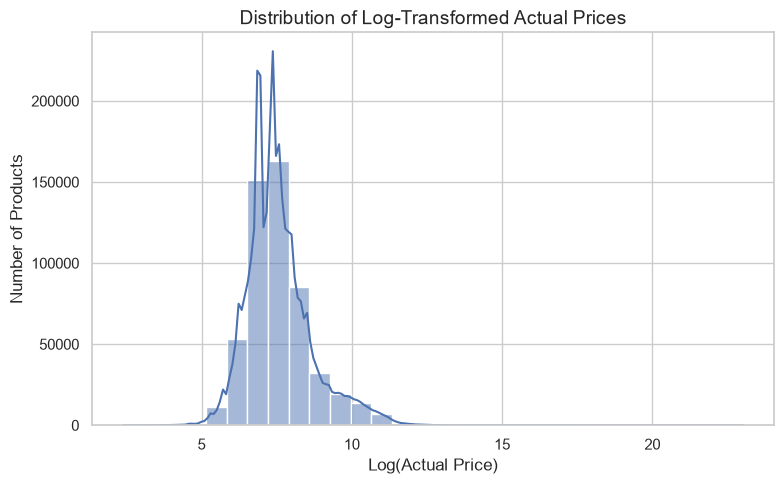

In [51]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='log_actual_price',
    bins=30,
    kde=True
)

plt.title('Distribution of Log-Transformed Actual Prices', fontsize=14)
plt.xlabel('Log(Actual Price)')
plt.ylabel('Number of Products')

plt.tight_layout()

plt.show()

### Insight

The original price distribution was highly right-skewed due to a small number of very expensive products. After applying a logarithmic transformation, the distribution becomes more balanced, making it easier to identify the overall pattern of product prices.

## Distribution of Discounted Product Prices

The discounted prices exhibit a right-skewed distribution. A logarithmic transformation is applied to improve the visualization by reducing the effect of extreme values.

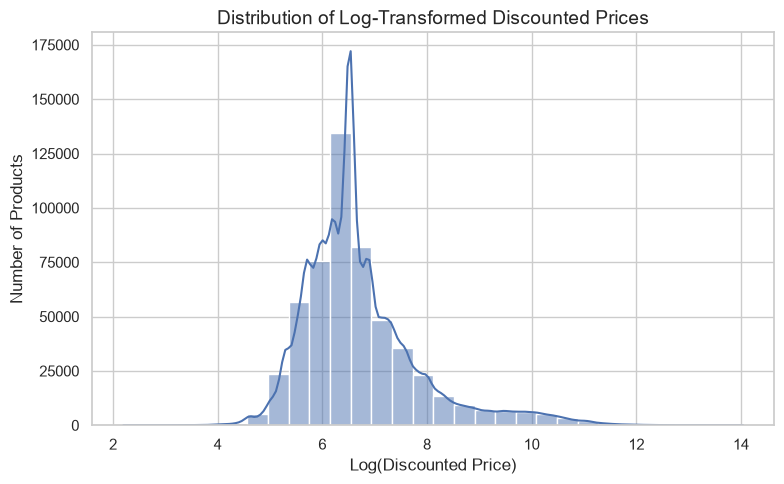

In [52]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='log_discount_price',
    bins=30,
    kde=True
)

plt.title('Distribution of Log-Transformed Discounted Prices', fontsize=14)
plt.xlabel('Log(Discounted Price)')
plt.ylabel('Number of Products')

plt.tight_layout()

plt.show()

### Insight

The original discounted prices were highly right-skewed, with a small number of products having exceptionally high discounted prices. The logarithmic transformation reduces this skewness, resulting in a clearer representation of the overall price distribution.

## Distribution of Number of Customer Ratings

The number of customer ratings is highly right-skewed, with a small number of products receiving exceptionally large numbers of reviews. A logarithmic transformation is applied to better visualize the distribution.

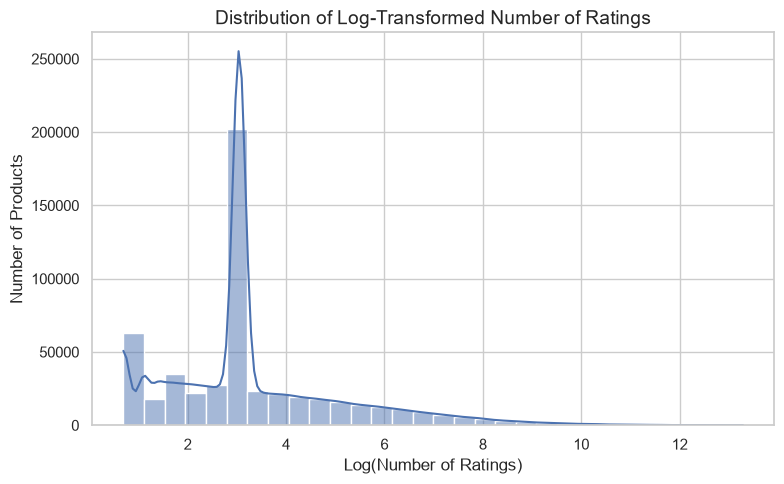

In [53]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='log_no_of_ratings',
    bins=30,
    kde=True
)

plt.title('Distribution of Log-Transformed Number of Ratings', fontsize=14)
plt.xlabel('Log(Number of Ratings)')
plt.ylabel('Number of Products')

plt.tight_layout()

plt.show()

### Insight

The original number of customer ratings was highly right-skewed, with only a small proportion of products receiving a very large number of reviews. After applying the logarithmic transformation, the distribution becomes more balanced, making it easier to observe the overall review pattern across products.

## Distribution of Discount Percentage

This histogram visualizes the distribution of discount percentages across products to understand how discounts are generally offered in the marketplace.

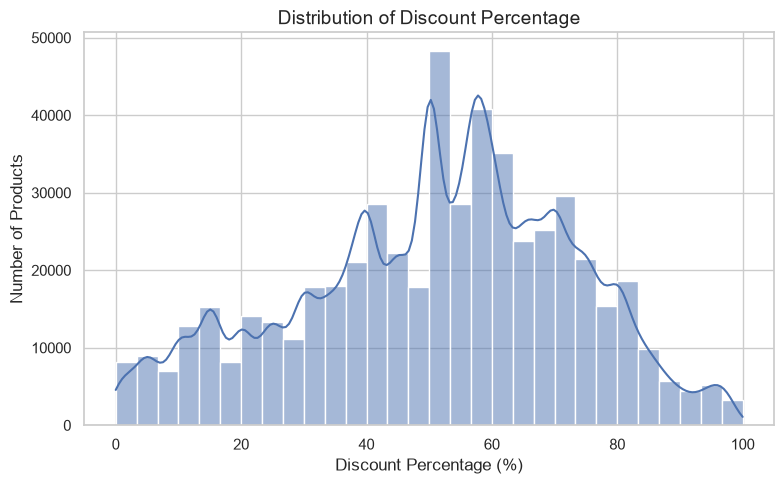

In [54]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='discount_percentage',
    bins=30,
    kde=True
)

plt.title('Distribution of Discount Percentage', fontsize=14)
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Number of Products')

plt.tight_layout()

plt.show()

### Insight

The distribution shows that discount percentages vary across products, with most products clustered within a specific discount range. Only a small proportion of products receive exceptionally high or low discounts, indicating that promotional strategies are generally concentrated around moderate discount levels.

## Average Customer Rating by Main Category

This chart compares the average customer rating across the main product categories to identify which categories receive the highest customer satisfaction.

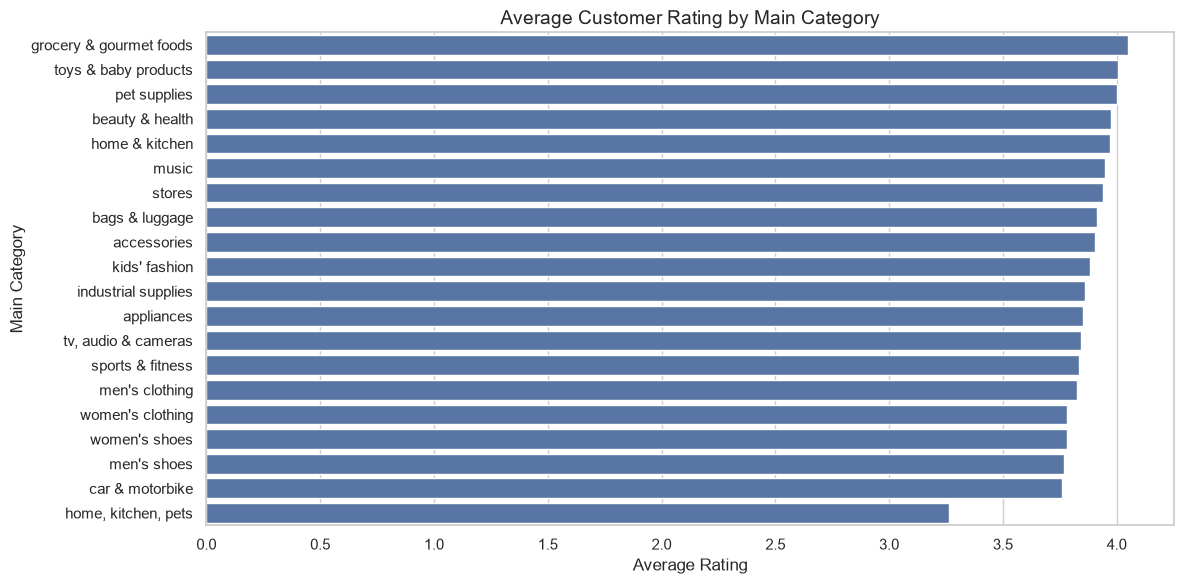

In [55]:
order = (
    df.groupby('main_category')['ratings']
      .mean()
      .sort_values(ascending=False)
      .index
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=df,
    y='main_category',
    x='ratings',
    order=order,
    errorbar=None
)

plt.title('Average Customer Rating by Main Category', fontsize=14)
plt.xlabel('Average Rating')
plt.ylabel('Main Category')

plt.tight_layout()

plt.show()

### Insight

The average ratings across the main categories are relatively similar, indicating consistently positive customer feedback throughout the marketplace. While a few categories achieve slightly higher average ratings, the differences are modest, suggesting that customer satisfaction is generally high regardless of product category.

## median Discount Percentage by Main Category

This chart compares the median discount percentage across the main product categories to identify which categories offer the highest discounts.

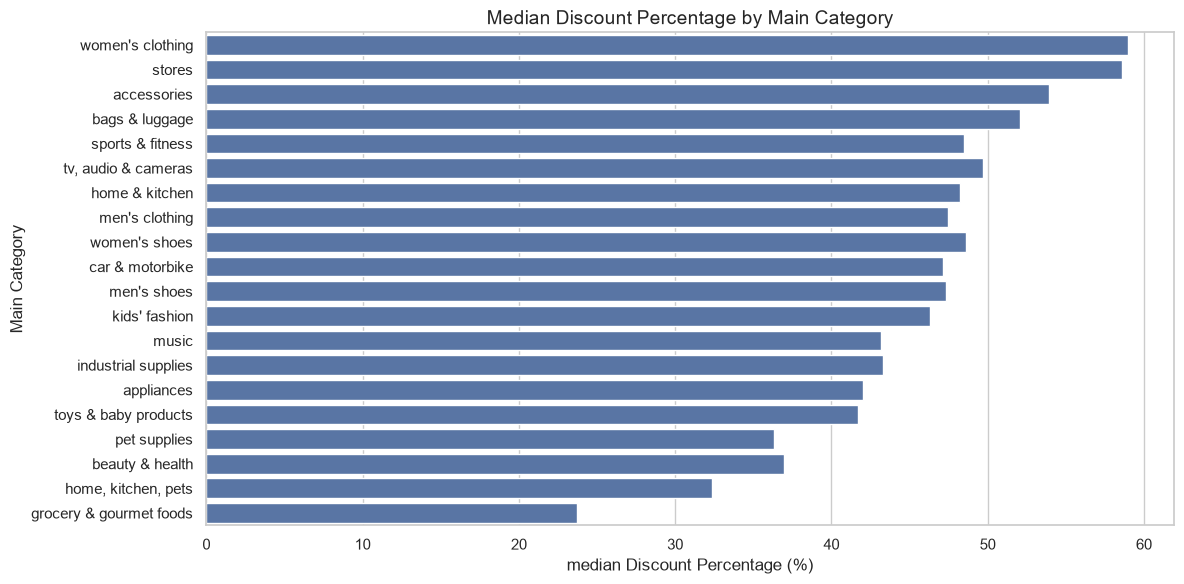

In [56]:
order = (
    df.groupby('main_category')['discount_percentage']
      .median()
      .sort_values(ascending=False)
      .index
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=df,
    y='main_category',
    x='discount_percentage',
    order=order,
    errorbar=None
)

plt.title('Median Discount Percentage by Main Category', fontsize=14)
plt.xlabel('median Discount Percentage (%)')
plt.ylabel('Main Category')

plt.tight_layout()

plt.show()

### Insight

The median discount percentage varies noticeably across product categories. Some categories consistently offer larger discounts, indicating more aggressive promotional strategies, while others maintain relatively lower discount levels.

## median Actual Price by Main Category

This chart compares the median actual product price across the main categories. A logarithmic scale is applied to the price axis to improve the visualization of categories with large differences in median prices.

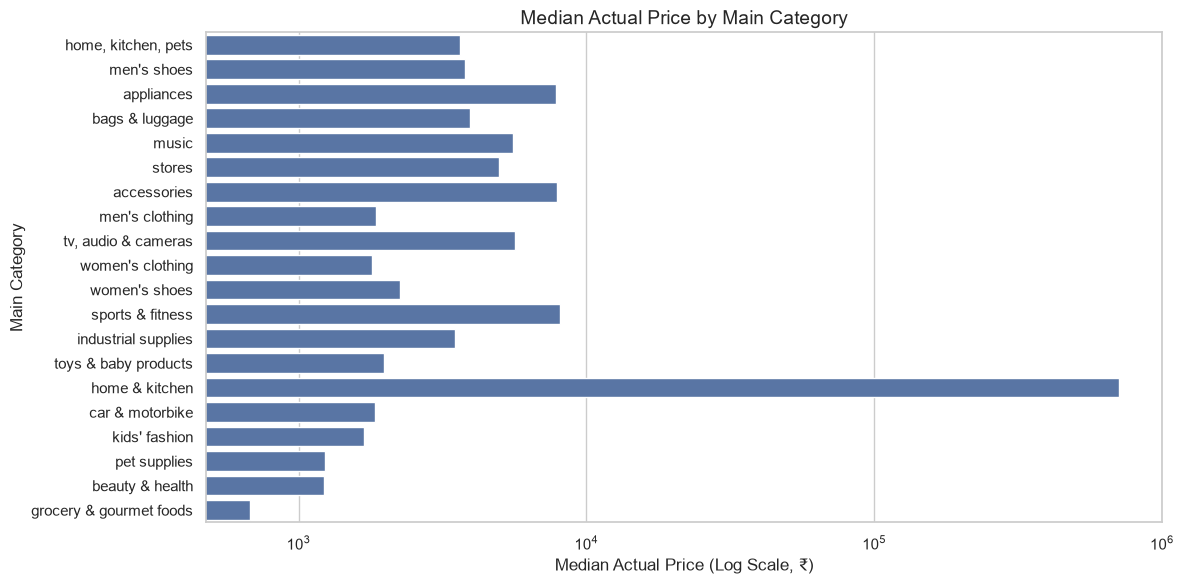

In [57]:
order = (
    df.groupby('main_category')['actual_price']
      .median()
      .sort_values(ascending=False)
      .index
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=df,
    y='main_category',
    x='actual_price',
    order=order,
    errorbar=None
)

plt.xscale('log')

plt.title('Median Actual Price by Main Category', fontsize=14)
plt.xlabel('Median Actual Price (Log Scale, ₹)')
plt.ylabel('Main Category')

plt.tight_layout()

plt.show()

### Insight

The median product price varies considerably across the main categories. A logarithmic scale is used to improve readability by reducing the influence of categories with exceptionally high median prices, allowing for a more meaningful comparison across all categories.

## Relationship Between Product Price and Customer Rating

The following visualizations compare the relationship between customer ratings and product prices using both the original price values and the log-transformed prices. This comparison illustrates how logarithmic transformation improves the visibility of patterns in highly skewed data.

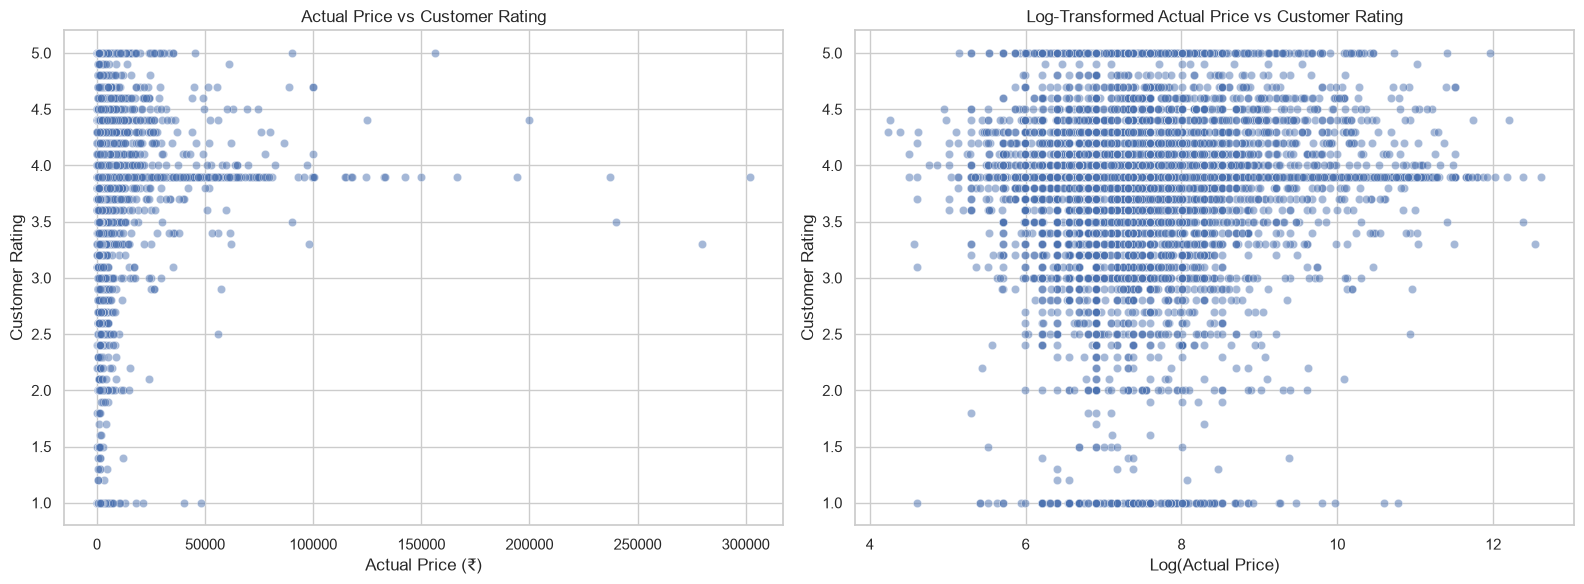

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x='actual_price',
    y='ratings',
    alpha=0.5,
    ax=axes[0]
)

axes[0].set_title('Actual Price vs Customer Rating')
axes[0].set_xlabel('Actual Price (₹)')
axes[0].set_ylabel('Customer Rating')

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x='log_actual_price',
    y='ratings',
    alpha=0.5,
    ax=axes[1]
)

axes[1].set_title('Log-Transformed Actual Price vs Customer Rating')
axes[1].set_xlabel('Log(Actual Price)')
axes[1].set_ylabel('Customer Rating')

plt.tight_layout()
plt.show()

### Insight

Both visualizations indicate that there is no strong relationship between product price and customer rating. However, the log-transformed price provides a clearer representation of products across different price levels by reducing the influence of extremely expensive products.

## Relationship Between Discounted Price and Customer Rating

The following visualizations compare the relationship between customer ratings and discounted prices using both the original values and the log-transformed prices. This comparison demonstrates how logarithmic transformation improves the visualization of highly skewed price data.

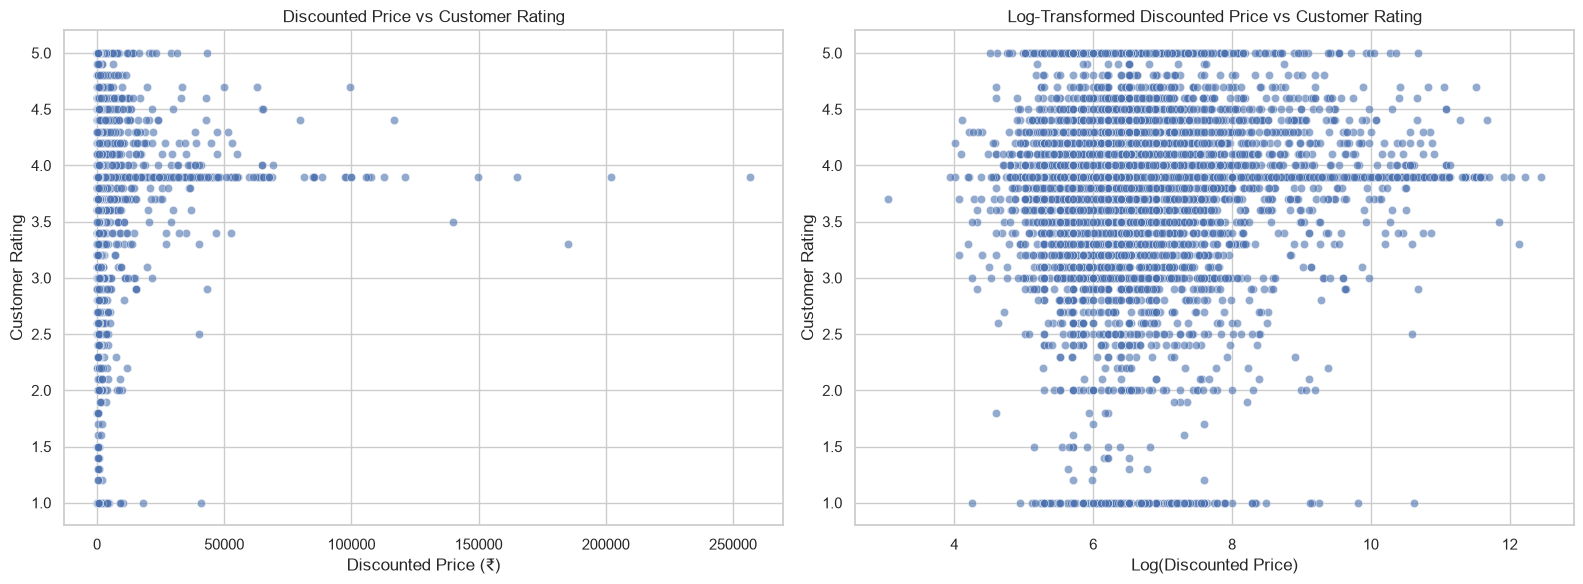

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x='discount_price',
    y='ratings',
    alpha=0.6,
    ax=axes[0]
)

axes[0].set_title('Discounted Price vs Customer Rating')
axes[0].set_xlabel('Discounted Price (₹)')
axes[0].set_ylabel('Customer Rating')

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x='log_discount_price',
    y='ratings',
    alpha=0.6,
    ax=axes[1]
)

axes[1].set_title('Log-Transformed Discounted Price vs Customer Rating')
axes[1].set_xlabel('Log(Discounted Price)')
axes[1].set_ylabel('Customer Rating')

plt.tight_layout()

plt.show()

### Insight

Both plots suggest that discounted price has little influence on customer ratings. The log-transformed visualization provides a clearer view of products across a wide range of discounted prices by reducing visual compression caused by extreme values

## Relationship Between Number of Ratings and Customer Rating

The following visualizations compare the relationship between customer ratings and the number of customer reviews using both the original values and the log-transformed values. This comparison demonstrates how logarithmic transformation improves the visualization of highly skewed review counts.

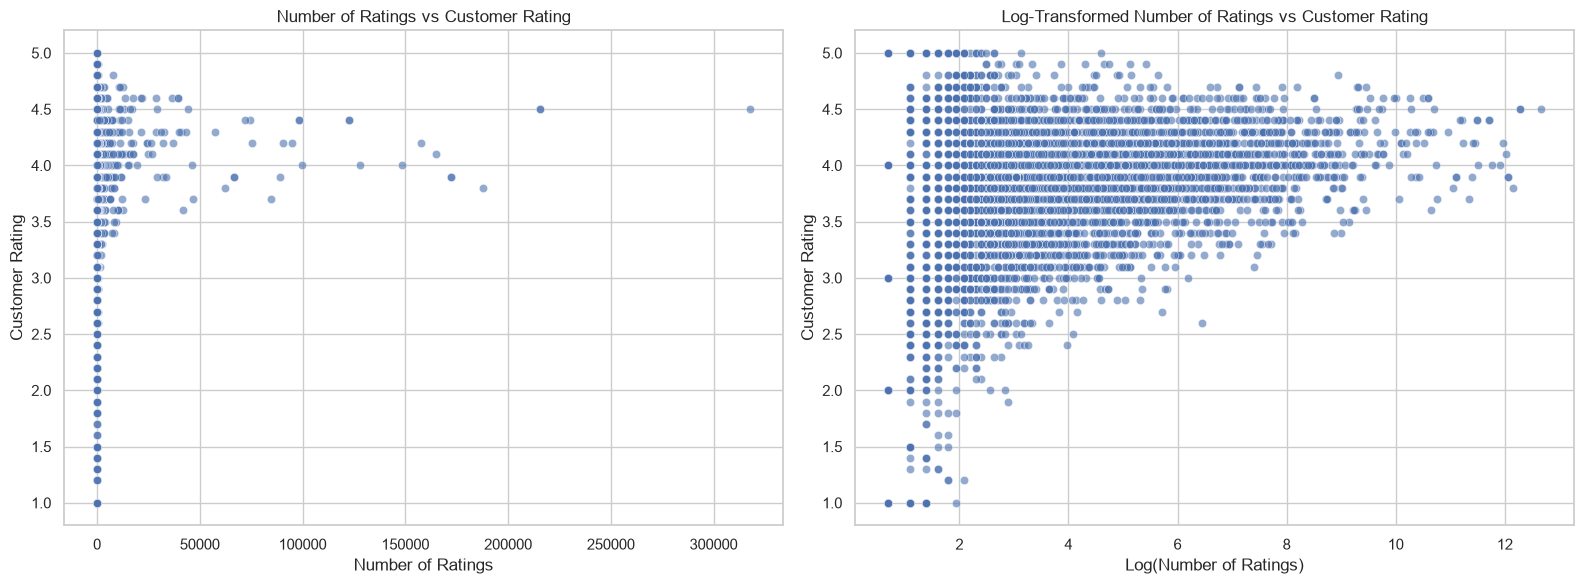

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))

sample = df.sample(10000, random_state=42)

sns.scatterplot(
    data=sample,
    x='no_of_ratings',
    y='ratings',
    alpha=0.6,
    ax=axes[0]
)

axes[0].set_title('Number of Ratings vs Customer Rating')
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Customer Rating')

sns.scatterplot(
    data=sample,
    x='log_no_of_ratings',
    y='ratings',
    alpha=0.6,
    ax=axes[1]
)

axes[1].set_title('Log-Transformed Number of Ratings vs Customer Rating')
axes[1].set_xlabel('Log(Number of Ratings)')
axes[1].set_ylabel('Customer Rating')

plt.tight_layout()

plt.show()

### Insight

The original plot is heavily concentrated because a small number of products have exceptionally high review counts. After applying the logarithmic transformation, the distribution becomes more balanced, making it easier to observe that products with both low and high numbers of reviews can still receive similarly high customer ratings. No strong relationship is observed between the number of reviews and the average customer rating.

## Distribution of Actual Product Prices by Main Category

This boxplot compares the distribution of actual product prices across the main categories. A logarithmic scale is applied to the price axis to improve the visualization of categories with wide price ranges.

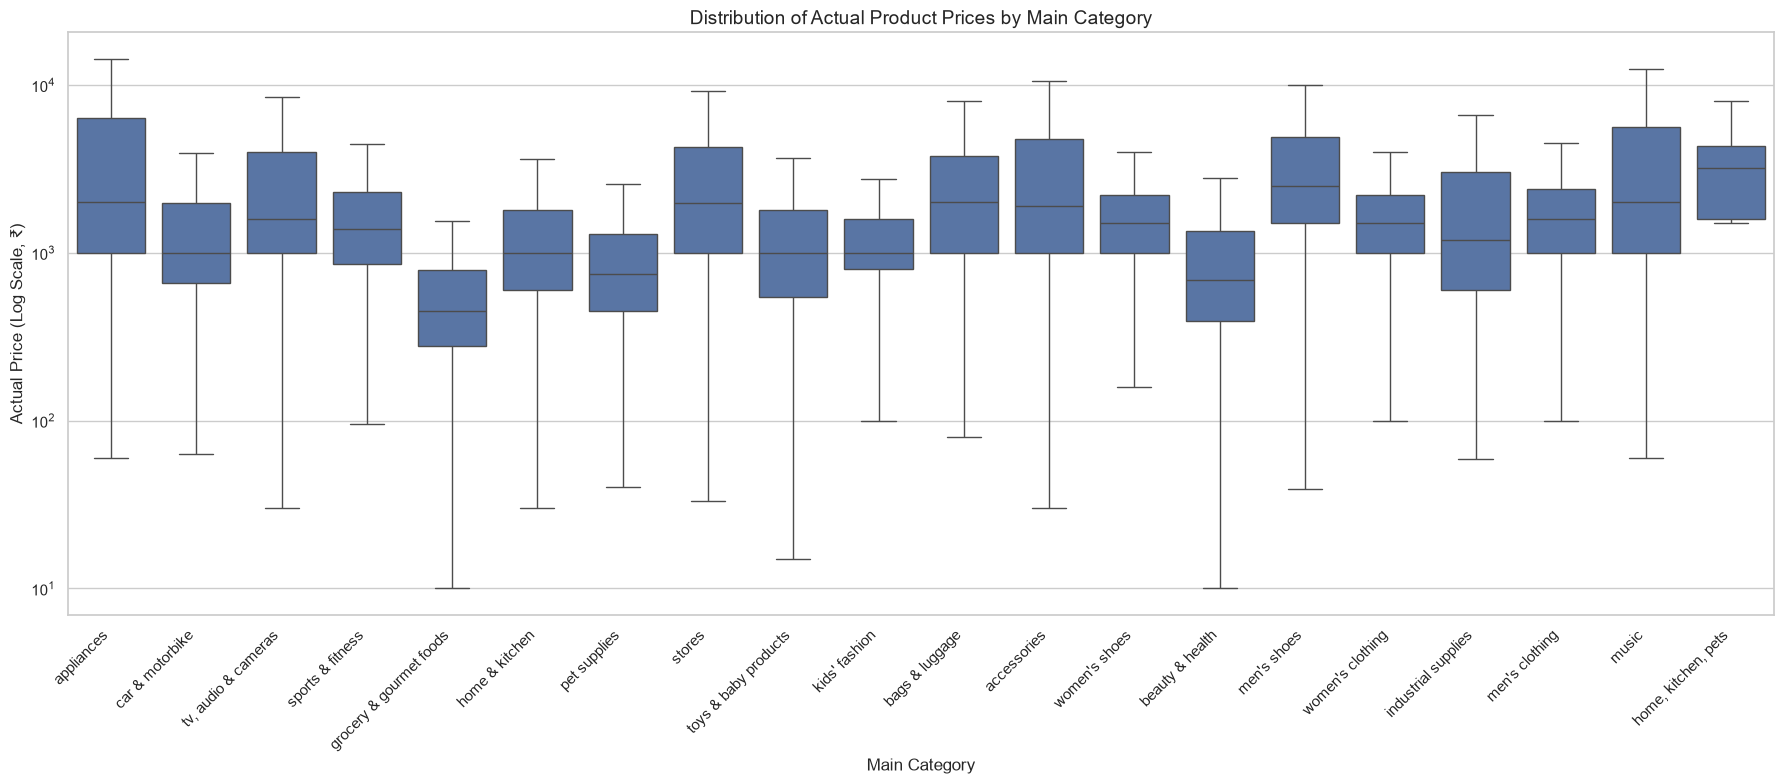

In [61]:
plt.figure(figsize=(18,8))

sns.boxplot(
    data=df,
    x='main_category',
    y='actual_price',
    showfliers=False 
)

plt.yscale('log')

plt.title('Distribution of Actual Product Prices by Main Category', fontsize=14)
plt.xlabel('Main Category')
plt.ylabel('Actual Price (Log Scale, ₹)')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.show()

### Insight

Outliers are hidden from the visualization to improve readability, while the original data is retained for analysis.

## Number of Products by Main Category

Before comparing the average customer ratings, it is useful to examine the number of products in each category. This helps assess whether the average ratings are based on sufficiently large samples.

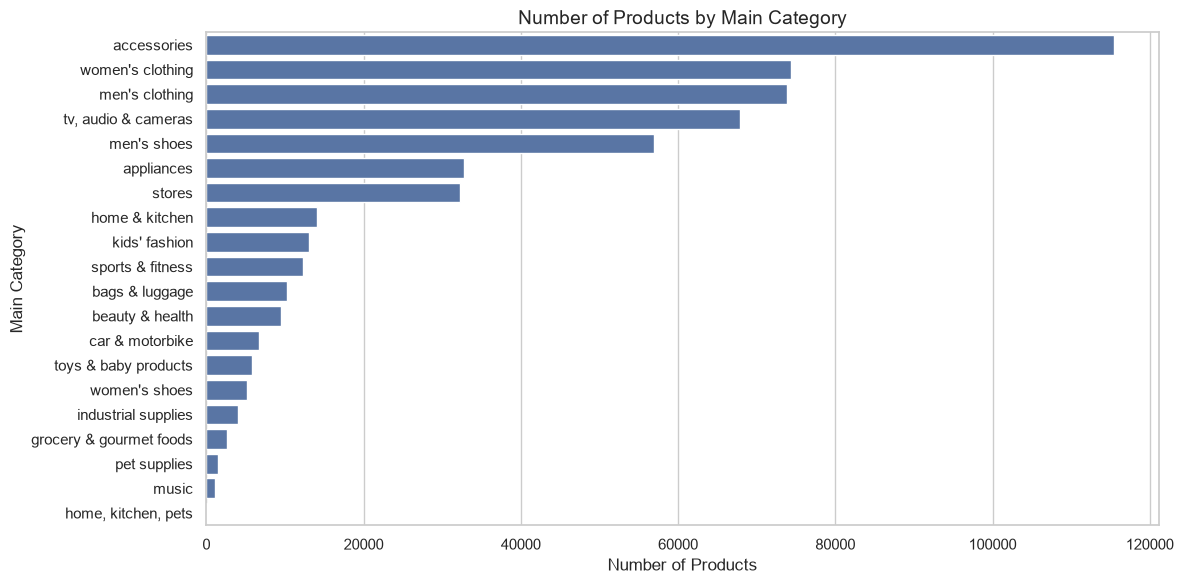

In [62]:
category_count = (
    df['main_category']
      .value_counts()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_count.values,
    y=category_count.index,
    errorbar=None
)


plt.title('Number of Products by Main Category', fontsize=14)
plt.xlabel('Number of Products')
plt.ylabel('Main Category')

plt.tight_layout()

plt.show()

### Insight

Product distribution varies across main categories, with some categories containing significantly more products than others.

## median Discounted Price by Main Category

This bar chart compares the median discounted price across the main product categories. A logarithmic scale is applied to the price axis to improve the comparison between categories with substantially different price ranges.

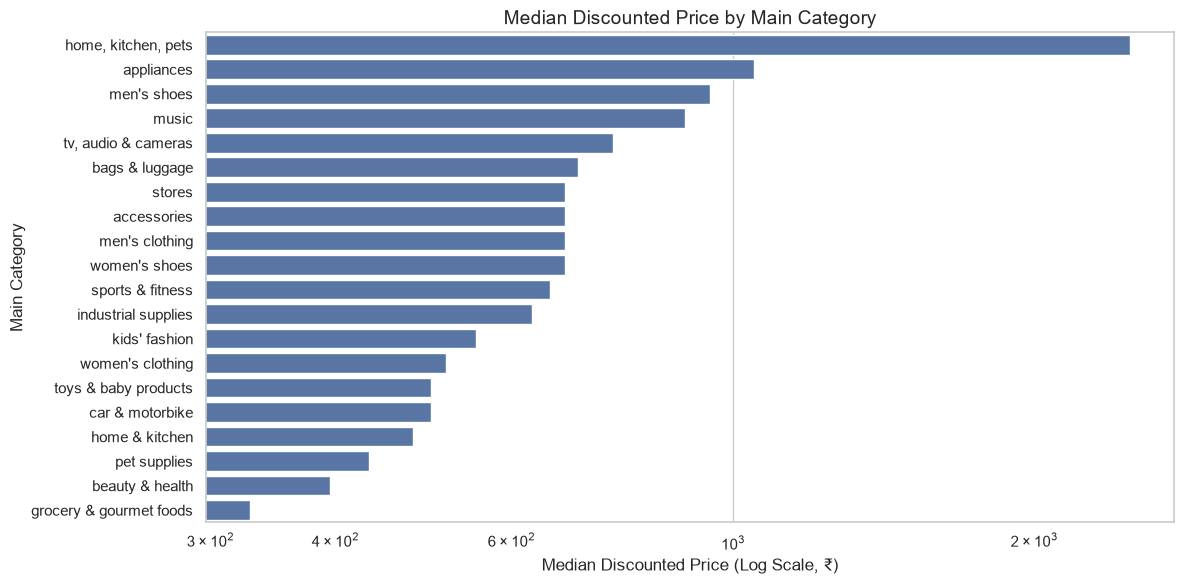

In [63]:
order = (
    df.groupby('main_category')['discount_price']
      .median()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=order.values,
    y=order.index,
    errorbar=None
)

plt.xscale('log')

plt.title('Median Discounted Price by Main Category', fontsize=14)
plt.xlabel('Median Discounted Price (Log Scale, ₹)')
plt.ylabel('Main Category')

plt.tight_layout()

plt.show()

### Insight

The median discounted price differs noticeably across the main product categories. A logarithmic scale improves readability by reducing the visual dominance of categories with substantially higher price values.

## median Number of Ratings by Main Category

This bar chart compares the median number of customer ratings across the main product categories. A logarithmic scale is applied to improve the comparison between categories with substantially different review counts.

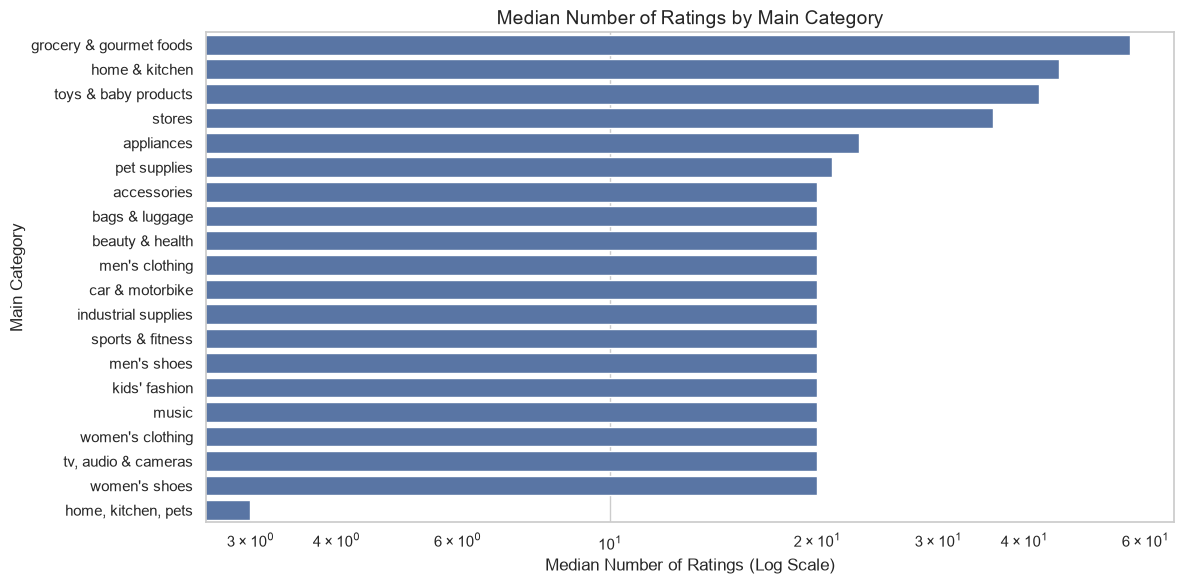

In [64]:
category_ratings = (
    df.groupby('main_category')['no_of_ratings']
      .median()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_ratings.values,
    y=category_ratings.index,
    errorbar=None
)

plt.xscale('log')

plt.title('Median Number of Ratings by Main Category', fontsize=14)
plt.xlabel('Median Number of Ratings (Log Scale)')
plt.ylabel('Main Category')

plt.tight_layout()

plt.show()

### Insight

The median number of customer ratings varies across the main product categories. Applying a logarithmic scale improves readability by reducing the impact of categories with exceptionally high review counts, making comparisons more meaningful.

## Top 10 Highest-Rated Sub-Categories with at Least 5,000 Total Ratings

This chart highlights the sub-categories that received the highest total number of customer ratings. A logarithmic scale is applied to improve the visualization of substantial differences in review volume.

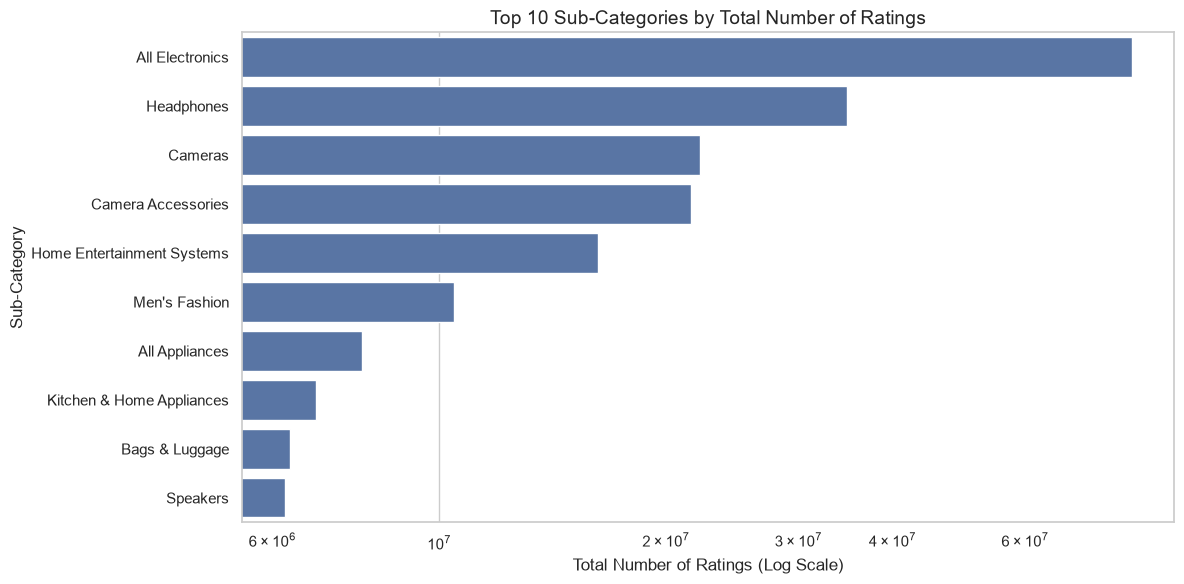

In [65]:
top = (
    df.groupby('sub_category')['no_of_ratings']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top.values,
    y=top.index,
    errorbar=None
)

plt.xscale('log')

plt.title('Top 10 Sub-Categories by Total Number of Ratings', fontsize=14)
plt.xlabel('Total Number of Ratings (Log Scale)')
plt.ylabel('Sub-Category')

plt.tight_layout()

plt.show()

### Insight

A small number of sub-categories account for a disproportionately large share of customer ratings. The logarithmic scale improves readability by reducing the visual dominance of categories with exceptionally high review counts.

## Top 10 Highest-Rated Sub-Categories

This chart displays the top 10 sub-categories with the highest average customer ratings. Only sub-categories with at least 5,000 customer ratings are included to ensure that the comparison is based on reliable customer feedback.

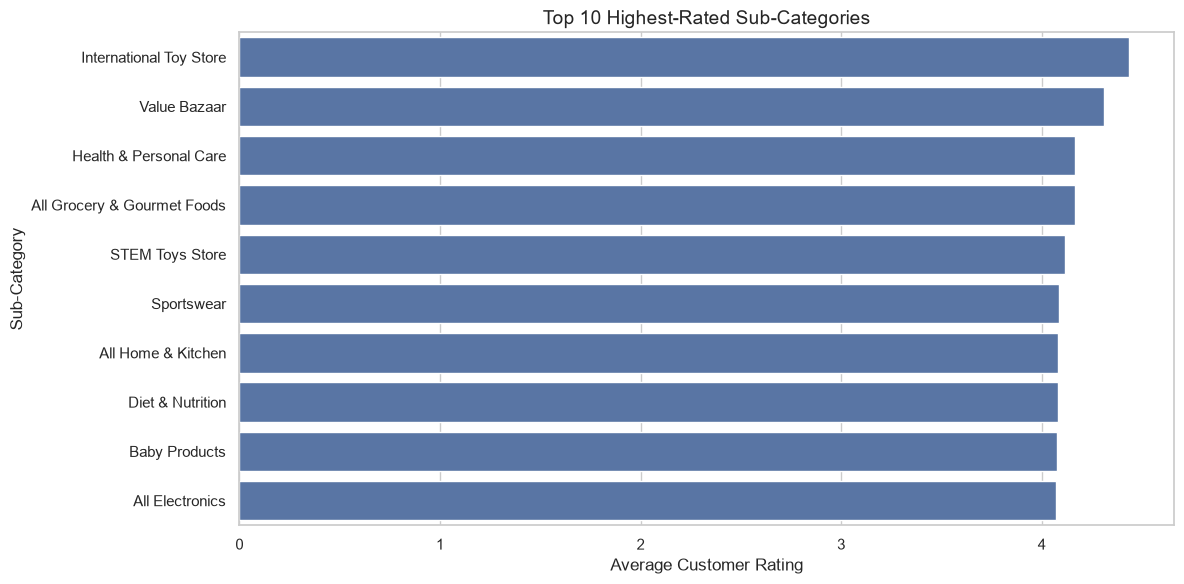

In [66]:
cat = (
    df.groupby('sub_category')
      .filter(lambda x: x['no_of_ratings'].sum() >= 5000)
)

top_10_rated = (
    cat.groupby('sub_category')['ratings']
       .mean()
       .sort_values(ascending=False)
       .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_rated.values,
    y=top_10_rated.index,
    errorbar=None
)

plt.title('Top 10 Highest-Rated Sub-Categories', fontsize=14)
plt.xlabel('Average Customer Rating')
plt.ylabel('Sub-Category')

plt.tight_layout()

plt.show()

### Insight

Several sub-categories consistently achieve higher average customer ratings than others. Filtering by the total number of customer ratings ensures that the rankings are based on substantial customer feedback rather than a small number of reviews, making the comparison more reliable.

## Correlation Matrix of Numeric Features

This heatmap illustrates the pairwise correlations among the key numerical features in the dataset. It helps identify strong relationships, potential multicollinearity, and variables that may be associated with customer ratings.

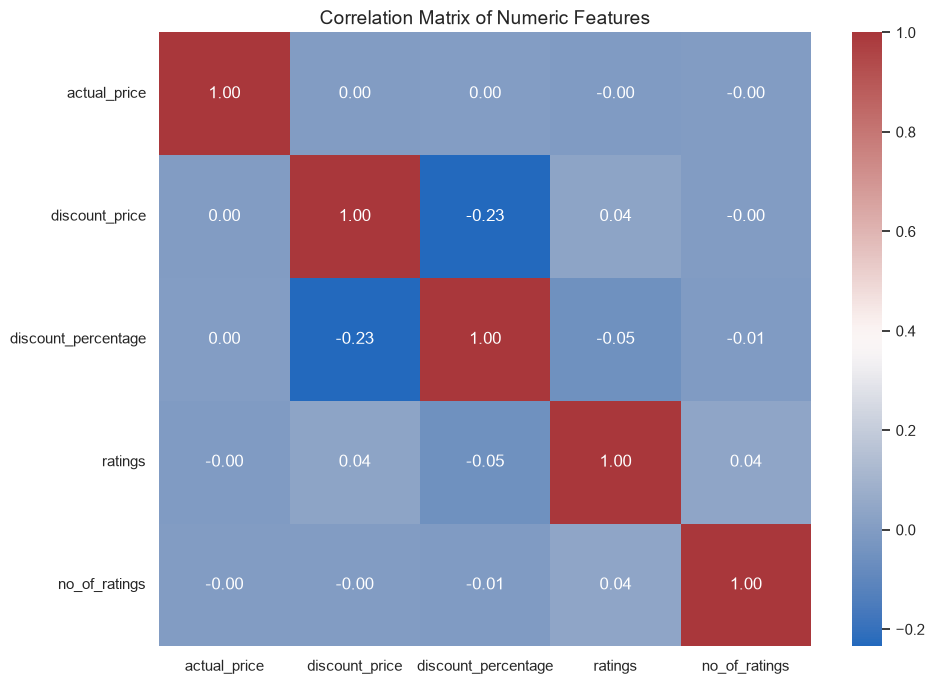

In [ ]:
numeric = [
    'actual_price',
    'discount_price',
    'discount_percentage',
    'ratings',
    'no_of_ratings'
]

correlation_matrix = df[numeric].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='vlag',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numeric Features', fontsize=14)

plt.tight_layout()

plt.show()

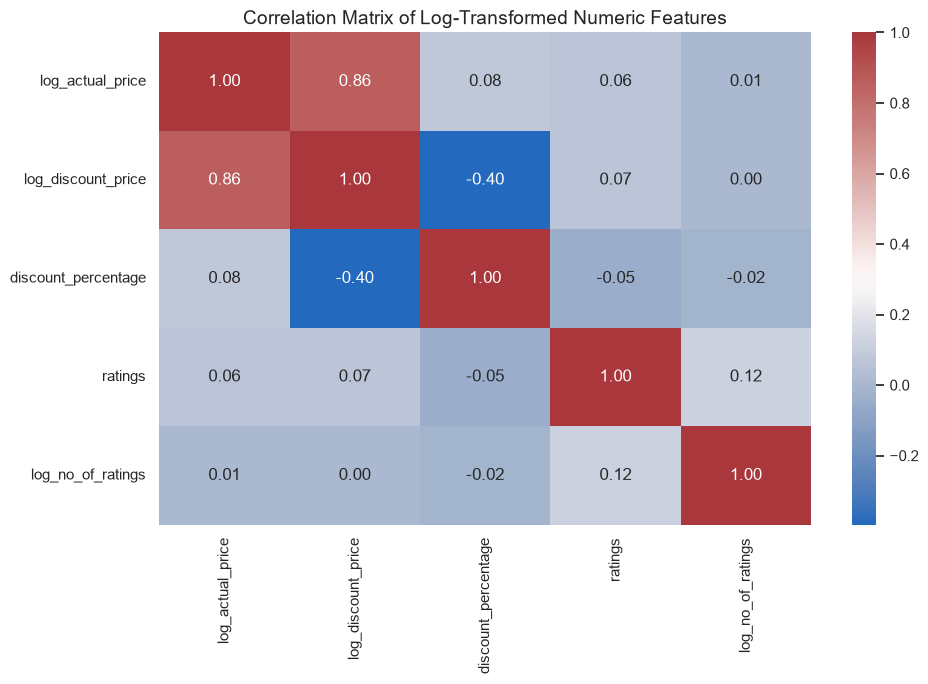

In [73]:
numeric_log = [
    'log_actual_price',
    'log_discount_price',
    'discount_percentage',
    'ratings',
    'log_no_of_ratings'
]

correlation_matrix = df[numeric_log].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='vlag',
    fmt='.2f'
)

plt.title('Correlation Matrix of Log-Transformed Numeric Features', fontsize=14)

plt.tight_layout()

plt.show()

### Insight

The heatmap shows a strong positive correlation between the actual and discounted prices, indicating that higher-priced products generally remain more expensive even after discounts. In contrast, customer ratings exhibit weak correlations with the pricing variables and the number of ratings, suggesting that customer satisfaction is influenced by factors beyond price and popularity alone.

# Key Findings

• Most products receive customer ratings between 3.5 and 4.5.

• Product prices are highly right-skewed, making logarithmic transformation appropriate.

• Actual price and discounted price exhibit a very strong positive correlation.

• Customer ratings show only weak relationships with price and review volume.

• Customer engagement is concentrated in a relatively small number of sub-categories.

• Discount percentage varies considerably across product categories.

• Several sub-categories consistently maintain high customer ratings based on substantial customer feedback.

# Conclusion

This analysis provides a comprehensive overview of Amazon product pricing, customer ratings, discounts, and category performance.

The findings can support pricing strategies, promotional planning, and category-level decision-making.

In [69]:
df.to_csv("amazon_cleaned.csv", index=False)